## Math 550 HW 6 Bucci Elisa

# Exercise 1

a) the best method is the subset selection.
For each $k$, best subset examines all $\binom{p}{k}$ models with $k$ predictors and picks the one with the lowest training RSS. The $k$-variable models found by forward and backward stepwise are among those candidates, so best subset's training RSS is always less than or equal to theirs (ties are possible when the stepwise path finds the same model).

b) The smallest test cannot be determined in general.
Best subset optimizes training RSS over a much larger space of models, so it is more prone to overfitting. A stepwise model may, by chance, generalize better. Best subset often performs well, but none of the three is guaranteed to have the lowest test RSS.

c) True or False
i. True: Forward stepwise obtains the $(k+1)$-variable model by *adding* one predictor to the $k$-variable model.

ii. True: Backward stepwise obtains the $k$-variable model by *removing* one predictor from the $(k+1)$-variable model.

iii. False: Forward and backward stepwise follow different paths; there is no reason for their models to be nested.

iv. False: Same reason as iii.

v. False: Best subset solves a separate optimization for each $k$, so the best models need not be nested. For example, the best single predictor could be $X_1$ while the best pair is $\{X_2, X_3\}$.

## Exercise 2

Recall that expected test MSE $=$ variance $+$ bias$^2$ $+$ irreducible error. A less flexible method has higher bias and lower variance; a more flexible method has lower bias and higher variance. A method improves prediction when what it gains is larger than what it gives up.

a) Lasso

The lasso minimizes RSS subject to $\sum_j |\beta_j| \le s$. The constraint shrinks the coefficients and can set some exactly to zero, so the lasso is less flexible than least squares.

- i. False. The lasso is less flexible, not more.
- ii. False. Wrong flexibility, and the trade is backwards.
- iii. True. Less flexible; it improves prediction when the increase in bias is smaller than the decrease in variance.
- iv. False. Right flexibility, but the trade is backwards: a less flexible method lowers variance, it does not raise it.

b) Ridge regression

Ridge minimizes RSS subject to $\sum_j \beta_j^2 \le s$. It shrinks all coefficients toward zero, so it is less flexible than least squares.

- i. False. Ridge is less flexible.
- ii. False. Wrong flexibility, and the trade is backwards.
- iii. True. It improves prediction when the decrease in variance is larger than the increase in bias.
- iv. False. The trade is backwards.

c) Non-linear methods

Non-linear methods (polynomials, splines, trees, ...) include the linear model as a special case, so they are more flexible than least squares.

- i. False. Right flexibility, but the trade is backwards: a more flexible method lowers bias, it does not raise it.
- ii. True. It improves prediction when the increase in variance is smaller than the decrease in bias.
- iii. False. Non-linear methods are more flexible.
- iv. False. Wrong flexibility.

## Exercise 7

Notation: $\mathrm{RSS} = \sum_{i=1}^n \big(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\big)^2$. The intercept $\beta_0$ is not penalized in lasso or ridge, so we give it a flat prior (equivalently, assume $X$ and $Y$ are centered).

a) Likelihood.
Since $\epsilon_i \overset{iid}{\sim} N(0,\sigma^2)$, the $y_i$ are independent with $y_i \sim N\big(\beta_0 + \sum_j x_{ij}\beta_j,\ \sigma^2\big)$:

$$
L(Y \mid X, \beta) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{\big(y_i - \beta_0 - \sum_j x_{ij}\beta_j\big)^2}{2\sigma^2}\right)
= (2\pi\sigma^2)^{-n/2} \exp\!\left(-\frac{\mathrm{RSS}}{2\sigma^2}\right).
$$

b) Posterior with the double-exponential prior.
With $p(\beta) = \prod_{j=1}^p \frac{1}{2b} e^{-|\beta_j|/b}$, Bayes' theorem gives

$$
p(\beta \mid X, Y) \propto L(Y \mid X, \beta)\, p(\beta) \propto \exp\!\left(-\frac{\mathrm{RSS}}{2\sigma^2} - \frac{1}{b}\sum_{j=1}^p |\beta_j|\right).
$$

c) The lasso estimate is the posterior mode.
The mode maximizes the posterior, i.e. minimizes the negative log-posterior:

$$
-\log p(\beta \mid X, Y) = \frac{\mathrm{RSS}}{2\sigma^2} + \frac{1}{b}\sum_j |\beta_j| + \text{const}.
$$

Multiplying by $2\sigma^2 > 0$ does not change the minimizer, so the mode solves

$$
\min_\beta \; \mathrm{RSS} + \lambda \sum_j |\beta_j|, \qquad \lambda = \frac{2\sigma^2}{b},
$$

which is exactly the lasso problem.

d) Posterior with the normal prior.
With $p(\beta) = \prod_{j=1}^p \frac{1}{\sqrt{2\pi c}} e^{-\beta_j^2/(2c)}$,

$$
p(\beta \mid X, Y) \propto \exp\!\left(-\frac{\mathrm{RSS}}{2\sigma^2} - \frac{1}{2c}\sum_{j=1}^p \beta_j^2\right).
$$

e) The ridge estimate is both the mode and the mean.

*Mode.* As in (c), taking $-\log$ and multiplying by $2\sigma^2$:

$$
\min_\beta \; \mathrm{RSS} + \lambda \sum_j \beta_j^2, \qquad \lambda = \frac{\sigma^2}{c},
$$

which is the ridge problem.

Mean. In matrix form (centered data), the exponent is

$$
-\frac{1}{2\sigma^2}\Big[(Y - X\beta)^\top (Y - X\beta) + \lambda \beta^\top \beta\Big]
= -\frac{1}{2\sigma^2}\Big[\beta^\top (X^\top X + \lambda I)\beta - 2\beta^\top X^\top Y\Big] + \text{const}.
$$

Completing the square with $A = X^\top X + \lambda I$:

$$
= -\frac{1}{2\sigma^2}(\beta - A^{-1}X^\top Y)^\top A\, (\beta - A^{-1}X^\top Y) + \text{const},
$$

so the posterior is Gaussian:

$$
\beta \mid X, Y \sim N\!\left((X^\top X + \lambda I)^{-1} X^\top Y,\ \sigma^2 (X^\top X + \lambda I)^{-1}\right).
$$

A normal distribution is symmetric and unimodal, so its mean equals its mode, and both equal $\hat\beta^{\text{ridge}} = (X^\top X + \lambda I)^{-1} X^\top Y$.

The Laplace posterior in (b) is not Gaussian, so for the lasso the mean and mode differ; only the mode coincides with the lasso estimate.

## Exercise 8

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

a) Generate $X$ and $\epsilon$ of length $n = 100$.

In [2]:
rng = np.random.default_rng(1)
n = 100
X = rng.normal(size=n)
eps = rng.normal(size=n)

b) Response with $\beta_0 = 1,\ \beta_1 = 2,\ \beta_2 = -3,\ \beta_3 = 0.5$.

In [3]:
Y = 1 + 2*X - 3*X**2 + 0.5*X**3 + eps

P = np.column_stack([X**k for k in range(1, 11)])   # predictors X, X^2, ..., X^10
names = [f"X^{k}" for k in range(1, 11)]

**Helper functions.** Forward/backward stepwise add or remove, at each step, the predictor that most reduces RSS. The final model size is chosen by
$C_p = \frac{1}{n}\big(\mathrm{RSS} + 2d\hat\sigma^2\big)$, with $\hat\sigma^2$ estimated from the full 10-predictor model.

In [4]:
def rss(cols, y):
    if not cols:
        return np.sum((y - y.mean())**2)
    fit = LinearRegression().fit(P[:, cols], y)
    return np.sum((y - fit.predict(P[:, cols]))**2)

def forward(y):
    path, cur, rem = [[]], [], list(range(10))
    while rem:
        best = min(rem, key=lambda j: rss(cur + [j], y))
        cur = cur + [best]; rem.remove(best); path.append(cur)
    return path

def backward(y):
    cur = list(range(10)); path = [cur]
    while cur:
        drop = min(cur, key=lambda j: rss([c for c in cur if c != j], y))
        cur = [c for c in cur if c != drop]; path.append(cur)
    return path[::-1]

def select_by_cp(path, y):
    s2 = rss(list(range(10)), y) / (n - 11)
    cp = [(rss(m, y) + 2*len(m)*s2) / n for m in path]
    k = int(np.argmin(cp))
    cols = sorted(path[k])
    fit = LinearRegression().fit(P[:, cols], y)
    print(f"Best model by Cp: k = {k}")
    print(f"  intercept  {fit.intercept_: .4f}")
    for j, b in zip(cols, fit.coef_):
        print(f"  {names[j]:9s}  {b: .4f}")

c) Forward stepwise selection.

In [5]:
select_by_cp(forward(Y), Y)

Best model by Cp: k = 4
  intercept   1.0534
  X^1         1.7756
  X^2        -3.2410
  X^3         0.6119
  X^10        0.0003


Forward stepwise selects $X, X^2, X^3$ (the true predictors) plus $X^{10}$, whose coefficient is essentially zero. The estimates of $\beta_1, \beta_2, \beta_3$ are close to the true values $2, -3, 0.5$.

d) Backward stepwise selection.

In [6]:
select_by_cp(backward(Y), Y)

Best model by Cp: k = 5
  intercept   1.0122
  X^1         2.3324
  X^2        -3.1566
  X^6        -0.0916
  X^7         0.0267
  X^8         0.0205


Backward stepwise gives a different model: it keeps $X$ and $X^2$ (with coefficients close to $2$ and $-3$) but drops $X^3$ early and replaces it with higher powers $X^6, X^7, X^8$. Because the powers of $X$ are highly correlated, $X^3$ is nearly redundant when all ten powers are in the model, and once removed it can never re-enter. Forward selection recovers the true model better in this case.

e) Lasso with $\lambda$ chosen by 10-fold cross-validation. The predictors are standardized first, since the powers of $X$ have very different scales; coefficients are then converted back to the original scale.

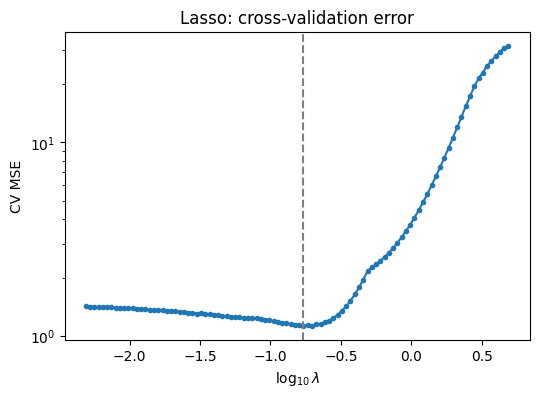

Optimal lambda = 0.1716
  intercept   0.8559
  X^1         1.9866
  X^2        -2.9460
  X^3         0.4267
  X^4        -0.0000
  X^5         0.0000
  X^6        -0.0000
  X^7         0.0000
  X^8         0.0000
  X^9        -0.0000
  X^10        0.0000


In [7]:
def fit_lasso(y):
    sc = StandardScaler().fit(P)
    las = LassoCV(cv=KFold(10, shuffle=True, random_state=0), max_iter=200_000).fit(sc.transform(P), y)
    coef = las.coef_ / sc.scale_
    intercept = las.intercept_ - np.sum(coef * sc.mean_)

    plt.figure(figsize=(6, 4))
    plt.plot(np.log10(las.alphas_), las.mse_path_.mean(axis=1), "o-", ms=3)
    plt.axvline(np.log10(las.alpha_), ls="--", color="gray")
    plt.xlabel(r"$\log_{10}\lambda$"); plt.ylabel("CV MSE"); plt.yscale("log")
    plt.title("Lasso: cross-validation error"); plt.show()

    print(f"Optimal lambda = {las.alpha_:.4f}")
    print(f"  intercept  {intercept: .4f}")
    for nm, b in zip(names, coef):
        print(f"  {nm:9s}  {b: .4f}")

fit_lasso(Y)

The lasso sets the coefficients of $X^4, \dots, X^{10}$ exactly to zero and keeps only $X, X^2, X^3$, i.e. it recovers the true model. The estimates are slightly shrunk toward zero (e.g. $\hat\beta_3 \approx 0.43$ vs. $0.5$), as expected from the penalty. Here the lasso performs best among the three methods.

f) New response $Y = \beta_0 + \beta_7 X^7 + \epsilon$ with $\beta_0 = 1,\ \beta_7 = 5$.

In [8]:
Y7 = 1 + 5*X**7 + eps

select_by_cp(forward(Y7), Y7)

Best model by Cp: k = 3
  intercept   0.9686
  X^4        -0.0417
  X^7         5.0162
  X^9        -0.0028


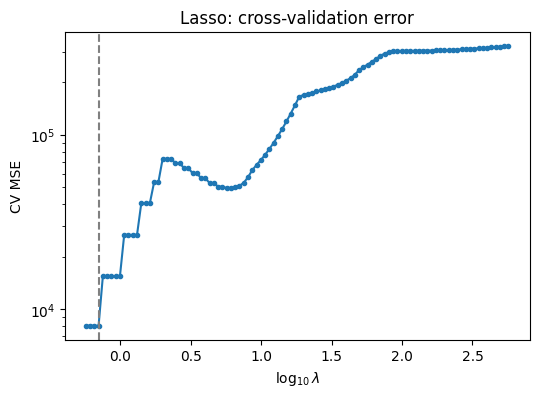

Optimal lambda = 0.7023
  intercept   1.0913
  X^1        -0.0000
  X^2        -0.0000
  X^3         0.0000
  X^4        -0.0000
  X^5         1.7715
  X^6        -0.0000
  X^7         4.3371
  X^8        -0.0000
  X^9         0.0564
  X^10       -0.0000


In [9]:
fit_lasso(Y7)

**Discussion.** Forward stepwise picks $X^7$ first and estimates $\hat\beta_7 \approx 5.02$, almost exactly the true value; Cp adds two extra terms ($X^4$, $X^9$) with negligible coefficients.

The lasso also selects $X^7$, but shrinks its coefficient noticeably ($\hat\beta_7 \approx 4.34$) and spreads part of the effect onto the correlated odd powers $X^5$ and $X^9$. Cross-validation chooses $\lambda$ to minimize prediction error, not to recover the true model, and with strongly correlated predictors the lasso tends to share weight among them.

So in this very sparse setting with one dominant signal, forward stepwise estimates the true coefficient more accurately, while in part (e) the lasso gave the cleanest model. In both cases, criteria aimed at prediction (Cp, CV) let in a few small spurious terms.